# ⚖️ EVALUASI v3 — Baseline (Naive, GARCH) + Uji Diebold–Mariano + Karakteristik Emiten
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Ilda Nurida — 6032251068 | Pembimbing: Dr. Ir. Ahmad Saikhu, S.Si, MT.**

Menggantikan `Baseline_GARCH_Volatility_LQ45.ipynb`. Seluruh model dievaluasi pada **tanggal uji yang identik** (1.500 hari-emiten).

| Model | Sumber prediksi |
|---|---|
| Naive | σ̂_{t+1} = σ_t (`Vol_Lag1`) |
| GARCH(1,1)-t | `GARCH_Forecast` dari PREP_01 v4 (expanding window, re-estimasi tiap 20 hari — **definisi yang sama** dengan fitur hybrid) |
| XGBoost hybrid | `hasil_prediksi_xgboost.csv` (MODEL_xgboost v4) |
| LSTM hybrid | `hasil_prediksi_lstm.csv` (MODEL_lstm v5) |

**Keluaran:** Tabel performa (→ Tabel VI), uji DM per emiten & gabungan (→ Reviewer 1 #2, Reviewer 2 #1), parameter GARCH (→ Tabel 4.x tesis), karakteristik volatilitas per emiten (→ Reviewer 2 #5), grafik aktual vs prediksi.

## ⚙️ CELL 1 — Konfigurasi & Muat Data

In [2]:
import os, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
warnings.filterwarnings('ignore')
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 9, 'figure.dpi': 150})

ROOT = Path.cwd()
for _ in range(6):
    if (ROOT / '03_dataset').exists(): break
    ROOT = ROOT.parent
if not (ROOT / '03_dataset').exists():
    ROOT = Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')
DIR_PROCESSED = ROOT / '03_dataset' / 'processed'
DIR_FINAL  = ROOT / '03_dataset' / 'final'
DIR_TABEL  = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'
for d in (DIR_TABEL, DIR_GAMBAR): d.mkdir(parents=True, exist_ok=True)
URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']
KOLOM_Y = 'Volatilitas_Target'

def inverse_transform(v, sc, kolom):
    cmin, cmax = float(sc.loc[kolom, 'min']), float(sc.loc[kolom, 'max'])
    return np.asarray(v, float) * (cmax - cmin) + cmin

rows = []
for e in URUTAN_EMITEN:
    te = pd.read_csv(DIR_FINAL / f'dataset_test_{e}.csv', encoding='utf-8-sig', parse_dates=['Date'])
    sc = pd.read_csv(DIR_FINAL / f'scaler_params_{e}.csv', index_col=0, encoding='utf-8-sig')
    rows.append(pd.DataFrame({'Emiten': e, 'Date': te['Date'],
                              'Aktual': inverse_transform(te[KOLOM_Y], sc, KOLOM_Y),
                              'Naive': inverse_transform(te['Vol_Lag1'], sc, 'Vol_Lag1'),
                              'GARCH(1,1)': inverse_transform(te['GARCH_Forecast'], sc, 'GARCH_Forecast')}))
df = pd.concat(rows, ignore_index=True)

for nama, f in [('XGBoost', 'hasil_prediksi_xgboost.csv'), ('LSTM', 'hasil_prediksi_lstm.csv')]:
    p = pd.read_csv(DIR_TABEL / f, encoding='utf-8-sig', parse_dates=['Date'])
    p = p[['Emiten', 'Date', 'Y_Aktual', 'Y_Prediksi']].rename(columns={'Y_Prediksi': nama, 'Y_Aktual': f'_akt_{nama}'})
    df = df.merge(p, on=['Emiten', 'Date'], how='left')
    assert df[nama].notna().all(), f'{nama}: ada tanggal uji tanpa prediksi → jalankan ulang notebook model versi terbaru'
    assert np.allclose(df[f'_akt_{nama}'], df['Aktual'], rtol=1e-6), f'{nama}: nilai aktual tidak cocok'
    df = df.drop(columns=f'_akt_{nama}')

MODELS = ['Naive', 'GARCH(1,1)', 'XGBoost', 'LSTM']
print(f'✅ {len(df):,} hari-emiten | tanggal uji identik untuk {MODELS}')

✅ 1,500 hari-emiten | tanggal uji identik untuk ['Naive', 'GARCH(1,1)', 'XGBoost', 'LSTM']


## 📋 CELL 2 — Tabel Performa (→ Tabel VI artikel)

In [3]:
def _mape(y, p): return float(np.mean(np.abs((y - p) / y)) * 100)
def metrik(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {'RMSE (1e-3)': np.sqrt(mean_squared_error(y, p)) * 1e3, 'MAE (1e-3)': mean_absolute_error(y, p) * 1e3,
            'MAPE (%)': _mape(y, p), 'R2': r2_score(y, p),
            'QLIKE': float(np.mean(np.log(p ** 2) + y ** 2 / p ** 2))}

tab = []
for m in MODELS:
    for e in URUTAN_EMITEN:
        g = df[df.Emiten == e]
        tab.append({'Model': m, 'Emiten': e, **metrik(g.Aktual, g[m])})
tab = pd.DataFrame(tab)
avg = tab.groupby('Model', sort=False).mean(numeric_only=True).reset_index().assign(Emiten='Average')
tab = pd.concat([tab, avg], ignore_index=True)
tab['_o'] = tab.Model.map({m: i for i, m in enumerate(MODELS)})
tab = tab.sort_values(['_o'], kind='stable').drop(columns='_o').reset_index(drop=True)
tab.round(4).to_csv(DIR_TABEL / 'tabel_performa_semua_model.csv', index=False, encoding='utf-8-sig')
pd.set_option('display.width', 200, 'display.max_columns', None)
print(tab.round({'RMSE (1e-3)': 3, 'MAE (1e-3)': 3, 'MAPE (%)': 2, 'R2': 4, 'QLIKE': 4}).to_string(index=False))

print('\nRingkasan rata-rata:')
print(tab[tab.Emiten == 'Average'].round(4).to_string(index=False))

     Model  Emiten  RMSE (1e-3)  MAE (1e-3)  MAPE (%)     R2   QLIKE
     Naive    ADRO        1.858       0.960      4.18 0.9131 -6.4993
     Naive    ADMR        3.615       1.680      4.81 0.9368 -5.6643
     Naive    ITMG        1.357       0.674      4.85 0.9794 -7.6889
     Naive    PTBA        1.556       0.720      4.75 0.9653 -7.4684
     Naive    MEDC        2.476       1.220      4.07 0.9346 -5.9996
     Naive    AKRA        1.587       0.943      4.25 0.9232 -6.5212
     Naive    PGAS        1.988       0.856      4.21 0.9452 -6.8295
     Naive Average        2.063       1.008      4.45 0.9425 -6.6673
GARCH(1,1)    ADRO        1.362       0.819      3.55 0.9533 -6.5051
GARCH(1,1)    ADMR        2.710       1.152      3.23 0.9645 -5.6739
GARCH(1,1)    ITMG        0.988       0.543      4.01 0.9891 -7.6962
GARCH(1,1)    PTBA        1.180       0.754      6.06 0.9800 -7.4740
GARCH(1,1)    MEDC        1.706       0.941      3.08 0.9690 -6.0050
GARCH(1,1)    AKRA        1.107   

## 🧪 CELL 3 — Uji Diebold–Mariano (MSE loss, koreksi Harvey–Leybourne–Newbold)
DM < 0 → model pertama lebih akurat. Diuji per emiten dan **gabungan 7 emiten** (loss dinormalisasi dengan varians target uji per emiten agar skala setara).

In [4]:
def diebold_mariano(d, h=1):
    d = np.asarray(d, float); n, dbar = len(d), d.mean()
    gamma = [np.sum((d[k:] - dbar) * (d[:n - k] - dbar)) / n for k in range(h)]
    var = (gamma[0] + 2 * sum(gamma[1:])) / n
    stat = dbar / np.sqrt(var) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return float(stat), float(2 * stats.t.sf(abs(stat), df=n - 1))

PASANGAN = [('XGBoost', 'GARCH(1,1)'), ('LSTM', 'GARCH(1,1)'), ('XGBoost', 'Naive'),
            ('LSTM', 'Naive'), ('GARCH(1,1)', 'Naive'), ('XGBoost', 'LSTM')]
hasil_dm = []
for a, b in PASANGAN:
    d_all = []
    for e in URUTAN_EMITEN:
        g = df[df.Emiten == e]
        d = (g.Aktual - g[a]) ** 2 - (g.Aktual - g[b]) ** 2
        s, p = diebold_mariano(d)
        hasil_dm.append({'Pembanding': f'{a} vs {b}', 'Emiten': e, 'DM': s, 'p_value': p})
        d_all.append(d / g.Aktual.var())          # normalisasi skala antar emiten
    s, p = diebold_mariano(pd.concat(d_all))
    hasil_dm.append({'Pembanding': f'{a} vs {b}', 'Emiten': 'Gabungan', 'DM': s, 'p_value': p})
df_dm = pd.DataFrame(hasil_dm)
df_dm['Kesimpulan'] = np.where(df_dm.p_value >= 0.05, 'tidak berbeda signifikan',
                        np.where(df_dm.DM < 0, df_dm.Pembanding.str.split(' vs ').str[0] + ' lebih akurat',
                                 df_dm.Pembanding.str.split(' vs ').str[1] + ' lebih akurat'))
df_dm.round(4).to_csv(DIR_TABEL / 'tabel_uji_dm_semua_model.csv', index=False, encoding='utf-8-sig')

piv = df_dm.pivot(index='Emiten', columns='Pembanding', values='p_value').reindex(URUTAN_EMITEN + ['Gabungan'])
tanda = df_dm.pivot(index='Emiten', columns='Pembanding', values='DM').reindex(URUTAN_EMITEN + ['Gabungan'])
ringkas = tanda.round(2).astype(str) + ' (' + piv.round(3).astype(str) + ')'
print('Statistik DM (p-value) — DM<0: model pertama lebih akurat\n')
print(ringkas[[f'{a} vs {b}' for a, b in PASANGAN]].to_string())
print('\nKesimpulan gabungan 7 emiten:')
print(df_dm[df_dm.Emiten == 'Gabungan'][['Pembanding', 'DM', 'p_value', 'Kesimpulan']].round(4).to_string(index=False))

Statistik DM (p-value) — DM<0: model pertama lebih akurat

Pembanding XGBoost vs GARCH(1,1) LSTM vs GARCH(1,1) XGBoost vs Naive  LSTM vs Naive GARCH(1,1) vs Naive XGBoost vs LSTM
Emiten                                                                                                                 
ADRO                2.68 (0.008)       1.16 (0.248)    -2.47 (0.014)  -3.13 (0.002)       -3.33 (0.001)    2.28 (0.024)
ADMR                0.35 (0.726)       0.28 (0.777)    -2.44 (0.016)  -2.46 (0.015)       -2.47 (0.014)    0.17 (0.864)
ITMG               -0.95 (0.343)       1.29 (0.197)    -3.13 (0.002)   -2.61 (0.01)        -3.0 (0.003)   -1.59 (0.114)
PTBA                -0.0 (0.997)      -1.58 (0.115)    -2.74 (0.007)   -3.0 (0.003)       -2.73 (0.007)    1.55 (0.122)
MEDC                 2.7 (0.008)       0.42 (0.677)    -2.12 (0.035)  -2.26 (0.025)       -2.28 (0.024)    2.26 (0.025)
AKRA                0.36 (0.719)       0.59 (0.553)      -4.01 (0.0)    -3.96 (0.0)         -4.03 (0.

In [12]:
# Loss per hari; QLIKE dalam bentuk varians (Patton, 2011): y²/p² − ln(y²/p²) − 1 ≥ 0
LOSS = {'MSE':   lambda y, p: (y - p) ** 2,
        'MAE':   lambda y, p: np.abs(y - p),
        'QLIKE': lambda y, p: y**2 / p**2 - np.log(y**2 / p**2) - 1}
# Normalisasi untuk uji gabungan agar skala antaremiten setara (QLIKE sudah bebas skala)
NORM = {'MSE': lambda y: y.var(), 'MAE': lambda y: y.std(), 'QLIKE': lambda y: 1.0}

rows = []
for nama_loss, f in LOSS.items():
    for a, b in PASANGAN:
        d_all = []
        for e in URUTAN_EMITEN:
            g = df[df.Emiten == e]
            d = f(g.Aktual, g[a]) - f(g.Aktual, g[b])
            s, p = diebold_mariano(d)
            rows.append({'Loss': nama_loss, 'Pembanding': f'{a} vs {b}', 'Emiten': e, 'DM': s, 'p_value': p})
            d_all.append(d / NORM[nama_loss](g.Aktual))
        s, p = diebold_mariano(pd.concat(d_all))
        rows.append({'Loss': nama_loss, 'Pembanding': f'{a} vs {b}', 'Emiten': 'Gabungan', 'DM': s, 'p_value': p})
df_dm_rob = pd.DataFrame(rows)
df_dm_rob['Kesimpulan'] = np.where(df_dm_rob.p_value >= 0.05, 'tidak berbeda signifikan',
                           np.where(df_dm_rob.DM < 0, df_dm_rob.Pembanding.str.split(' vs ').str[0] + ' lebih akurat',
                                    df_dm_rob.Pembanding.str.split(' vs ').str[1] + ' lebih akurat'))
df_dm_rob.round(4).to_csv(DIR_TABEL / 'tabel_uji_dm_robust_loss.csv', index=False, encoding='utf-8-sig')

for nama_loss in LOSS:
    s = df_dm_rob[df_dm_rob.Loss == nama_loss]
    t = (s.pivot(index='Emiten', columns='Pembanding', values='DM').round(2).astype(str) + ' ('
         + s.pivot(index='Emiten', columns='Pembanding', values='p_value').round(3).astype(str) + ')')
    print(f'\n=== Loss: {nama_loss} — DM (p-value), DM<0: model pertama lebih akurat ===')
    print(t.reindex(URUTAN_EMITEN + ['Gabungan'])[[f'{a} vs {b}' for a, b in PASANGAN]].to_string())
print('\n=== Ringkasan gabungan 7 emiten ===')
print(df_dm_rob[df_dm_rob.Emiten == 'Gabungan'].pivot(index='Pembanding', columns='Loss', values='Kesimpulan')
      .reindex([f'{a} vs {b}' for a, b in PASANGAN])[list(LOSS)].to_string())


=== Loss: MSE — DM (p-value), DM<0: model pertama lebih akurat ===
Pembanding XGBoost vs GARCH(1,1) LSTM vs GARCH(1,1) XGBoost vs Naive  LSTM vs Naive GARCH(1,1) vs Naive XGBoost vs LSTM
Emiten                                                                                                                 
ADRO                2.68 (0.008)       1.16 (0.248)    -2.47 (0.014)  -3.13 (0.002)       -3.33 (0.001)    2.28 (0.024)
ADMR                0.35 (0.726)       0.28 (0.777)    -2.44 (0.016)  -2.46 (0.015)       -2.47 (0.014)    0.17 (0.864)
ITMG               -0.95 (0.343)       1.29 (0.197)    -3.13 (0.002)   -2.61 (0.01)        -3.0 (0.003)   -1.59 (0.114)
PTBA                -0.0 (0.997)      -1.58 (0.115)    -2.74 (0.007)   -3.0 (0.003)       -2.73 (0.007)    1.55 (0.122)
MEDC                 2.7 (0.008)       0.42 (0.677)    -2.12 (0.035)  -2.26 (0.025)       -2.28 (0.024)    2.26 (0.025)
AKRA                0.36 (0.719)       0.59 (0.553)      -4.01 (0.0)    -3.96 (0.0)         

## 📐 CELL 4 — Parameter GARCH(1,1)-t pada Data Latih (→ Tabel 4.x tesis)

In [5]:
from arch import arch_model
tek = pd.read_csv(DIR_PROCESSED / 'technical_features.csv', parse_dates=['Date'])
rows = []
for e in URUTAN_EMITEN:
    tr_end = pd.read_csv(DIR_FINAL / f'dataset_train_{e}.csv', parse_dates=['Date'])['Date'].max()
    r = tek[(tek.Emiten == e) & (tek.Date <= tr_end)].sort_values('Date')['Log_Return'].dropna() * 100
    res = arch_model(r.values, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off')
    pr, pv = res.params, res.pvalues
    rows.append({'Emiten': e, 'n': len(r), 'mu': pr['mu'], 'omega': pr['omega'],
                 'alpha': pr['alpha[1]'], 'p_alpha': pv['alpha[1]'], 'beta': pr['beta[1]'], 'p_beta': pv['beta[1]'],
                 'alpha+beta': pr['alpha[1]'] + pr['beta[1]'], 'nu': pr['nu'],
                 'Half-life (hari)': np.log(0.5) / np.log(pr['alpha[1]'] + pr['beta[1]'])})
df_par = pd.DataFrame(rows)
df_par.round(4).to_csv(DIR_TABEL / 'tabel_parameter_garch.csv', index=False, encoding='utf-8-sig')
print('Return dalam persen (×100). alpha+beta mendekati 1 = volatility clustering kuat.')
print(df_par.round(4).to_string(index=False))

Return dalam persen (×100). alpha+beta mendekati 1 = volatility clustering kuat.
Emiten   n      mu  omega  alpha  p_alpha   beta  p_beta  alpha+beta     nu  Half-life (hari)
  ADRO 859  0.0740 1.4762 0.1541   0.0098 0.6617  0.0000      0.8158 3.6872            3.4049
  ADMR 840 -0.1755 0.0976 0.0234   0.0476 0.9666  0.0000      0.9900 6.0174           68.8409
  ITMG 859  0.0633 0.0254 0.0491   0.0451 0.9467  0.0000      0.9959 4.1841          167.3202
  PTBA 859  0.0036 1.5645 0.1962   0.0335 0.5186  0.1335      0.7148 3.2217            2.0648
  MEDC 859  0.0150 0.8305 0.1132   0.0926 0.8099  0.0000      0.9231 5.5074            8.6599
  AKRA 859  0.0263 0.0759 0.0500   0.1237 0.9446  0.0000      0.9946 3.6349          128.3788
  PGAS 859  0.0126 0.1040 0.0462   0.0731 0.9333  0.0000      0.9794 3.7313           33.3688


## 🔎 CELL 5 — Karakteristik Volatilitas per Emiten vs Kinerja Model (→ Reviewer 2 #5)

In [6]:
rows = []
for e in URUTAN_EMITEN:
    tr = pd.read_csv(DIR_FINAL / f'dataset_train_{e}.csv', parse_dates=['Date'])
    t = tek[tek.Emiten == e].sort_values('Date')
    v_tr = t[t.Date <= tr.Date.max()]['Volatilitas']; v_te = t[t.Date > tr.Date.max()]['Volatilitas']
    r_tr = t[t.Date <= tr.Date.max()]['Log_Return']
    ac1 = v_tr.autocorr(lag=1)
    r2 = tab[(tab.Emiten == e)].set_index('Model')['R2']
    rows.append({'Emiten': e, 'n_latih': len(tr), 'Mean vol latih': v_tr.mean(), 'Vol-of-vol (std)': v_tr.std(),
                 'Kurtosis return': r_tr.kurt(), 'AC(1) vol': ac1,
                 'Mean vol uji / latih': v_te.mean() / v_tr.mean(), 'Max vol uji / latih': v_te.max() / v_tr.max(),
                 'R2 XGBoost': r2['XGBoost'], 'R2 LSTM': r2['LSTM'], 'R2 GARCH': r2['GARCH(1,1)']})
df_kar = pd.DataFrame(rows)
df_kar.round(4).to_csv(DIR_TABEL / 'tabel_karakteristik_emiten.csv', index=False, encoding='utf-8-sig')
print(df_kar.round(4).to_string(index=False))
print('\nKorelasi (Spearman) karakteristik vs R2 antar 7 emiten:')
kar_cols = ['Vol-of-vol (std)', 'Kurtosis return', 'AC(1) vol', 'Max vol uji / latih']
print(df_kar[kar_cols + ['R2 XGBoost', 'R2 LSTM']].corr(method='spearman').loc[kar_cols, ['R2 XGBoost', 'R2 LSTM']].round(2).to_string())

Emiten  n_latih  Mean vol latih  Vol-of-vol (std)  Kurtosis return  AC(1) vol  Mean vol uji / latih  Max vol uji / latih  R2 XGBoost  R2 LSTM  R2 GARCH
  ADRO      859          0.0254            0.0122          16.3885     0.9762                0.9493               0.4649      0.9441   0.9517    0.9533
  ADMR      840          0.0333            0.0116           2.8555     0.9804                1.1397               0.7945      0.9643   0.9644    0.9645
  ITMG      859          0.0189            0.0076           3.7201     0.9830                0.8089               1.0172      0.9896   0.9882    0.9891
  PTBA      859          0.0198            0.0087          12.0801     0.9742                0.8279               0.5608      0.9800   0.9812    0.9800
  MEDC      859          0.0298            0.0100           3.0905     0.9761                1.0563               0.8391      0.9664   0.9686    0.9690
  AKRA      859          0.0242            0.0091           5.8421     0.9771           

## 📊 CELL 6 — Grafik Aktual vs Prediksi (satu emiten untuk artikel, semua emiten untuk tesis)

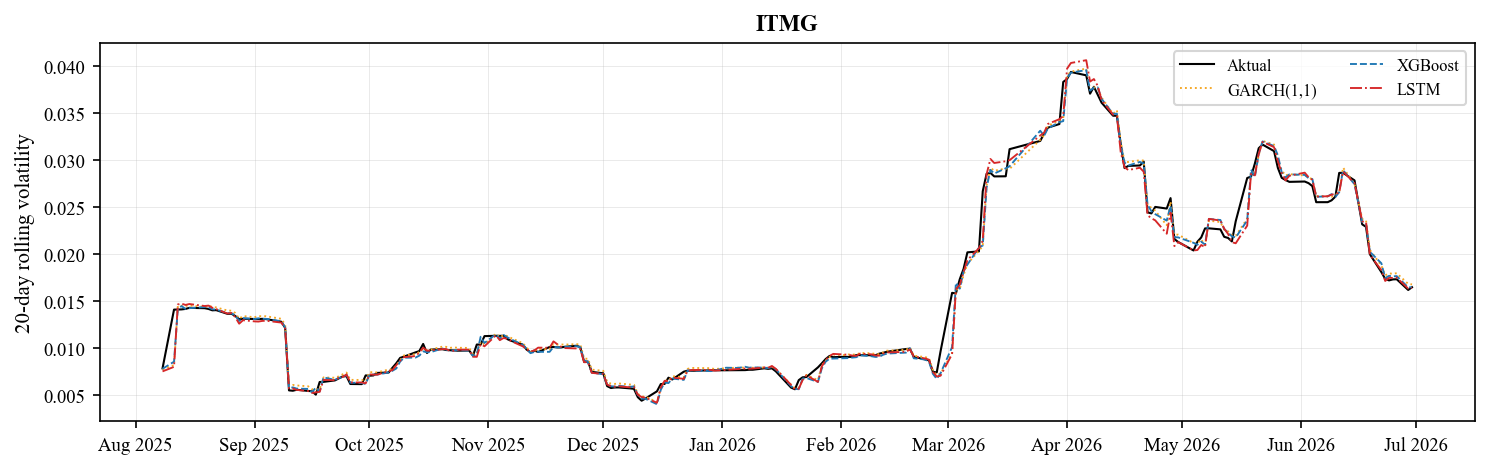

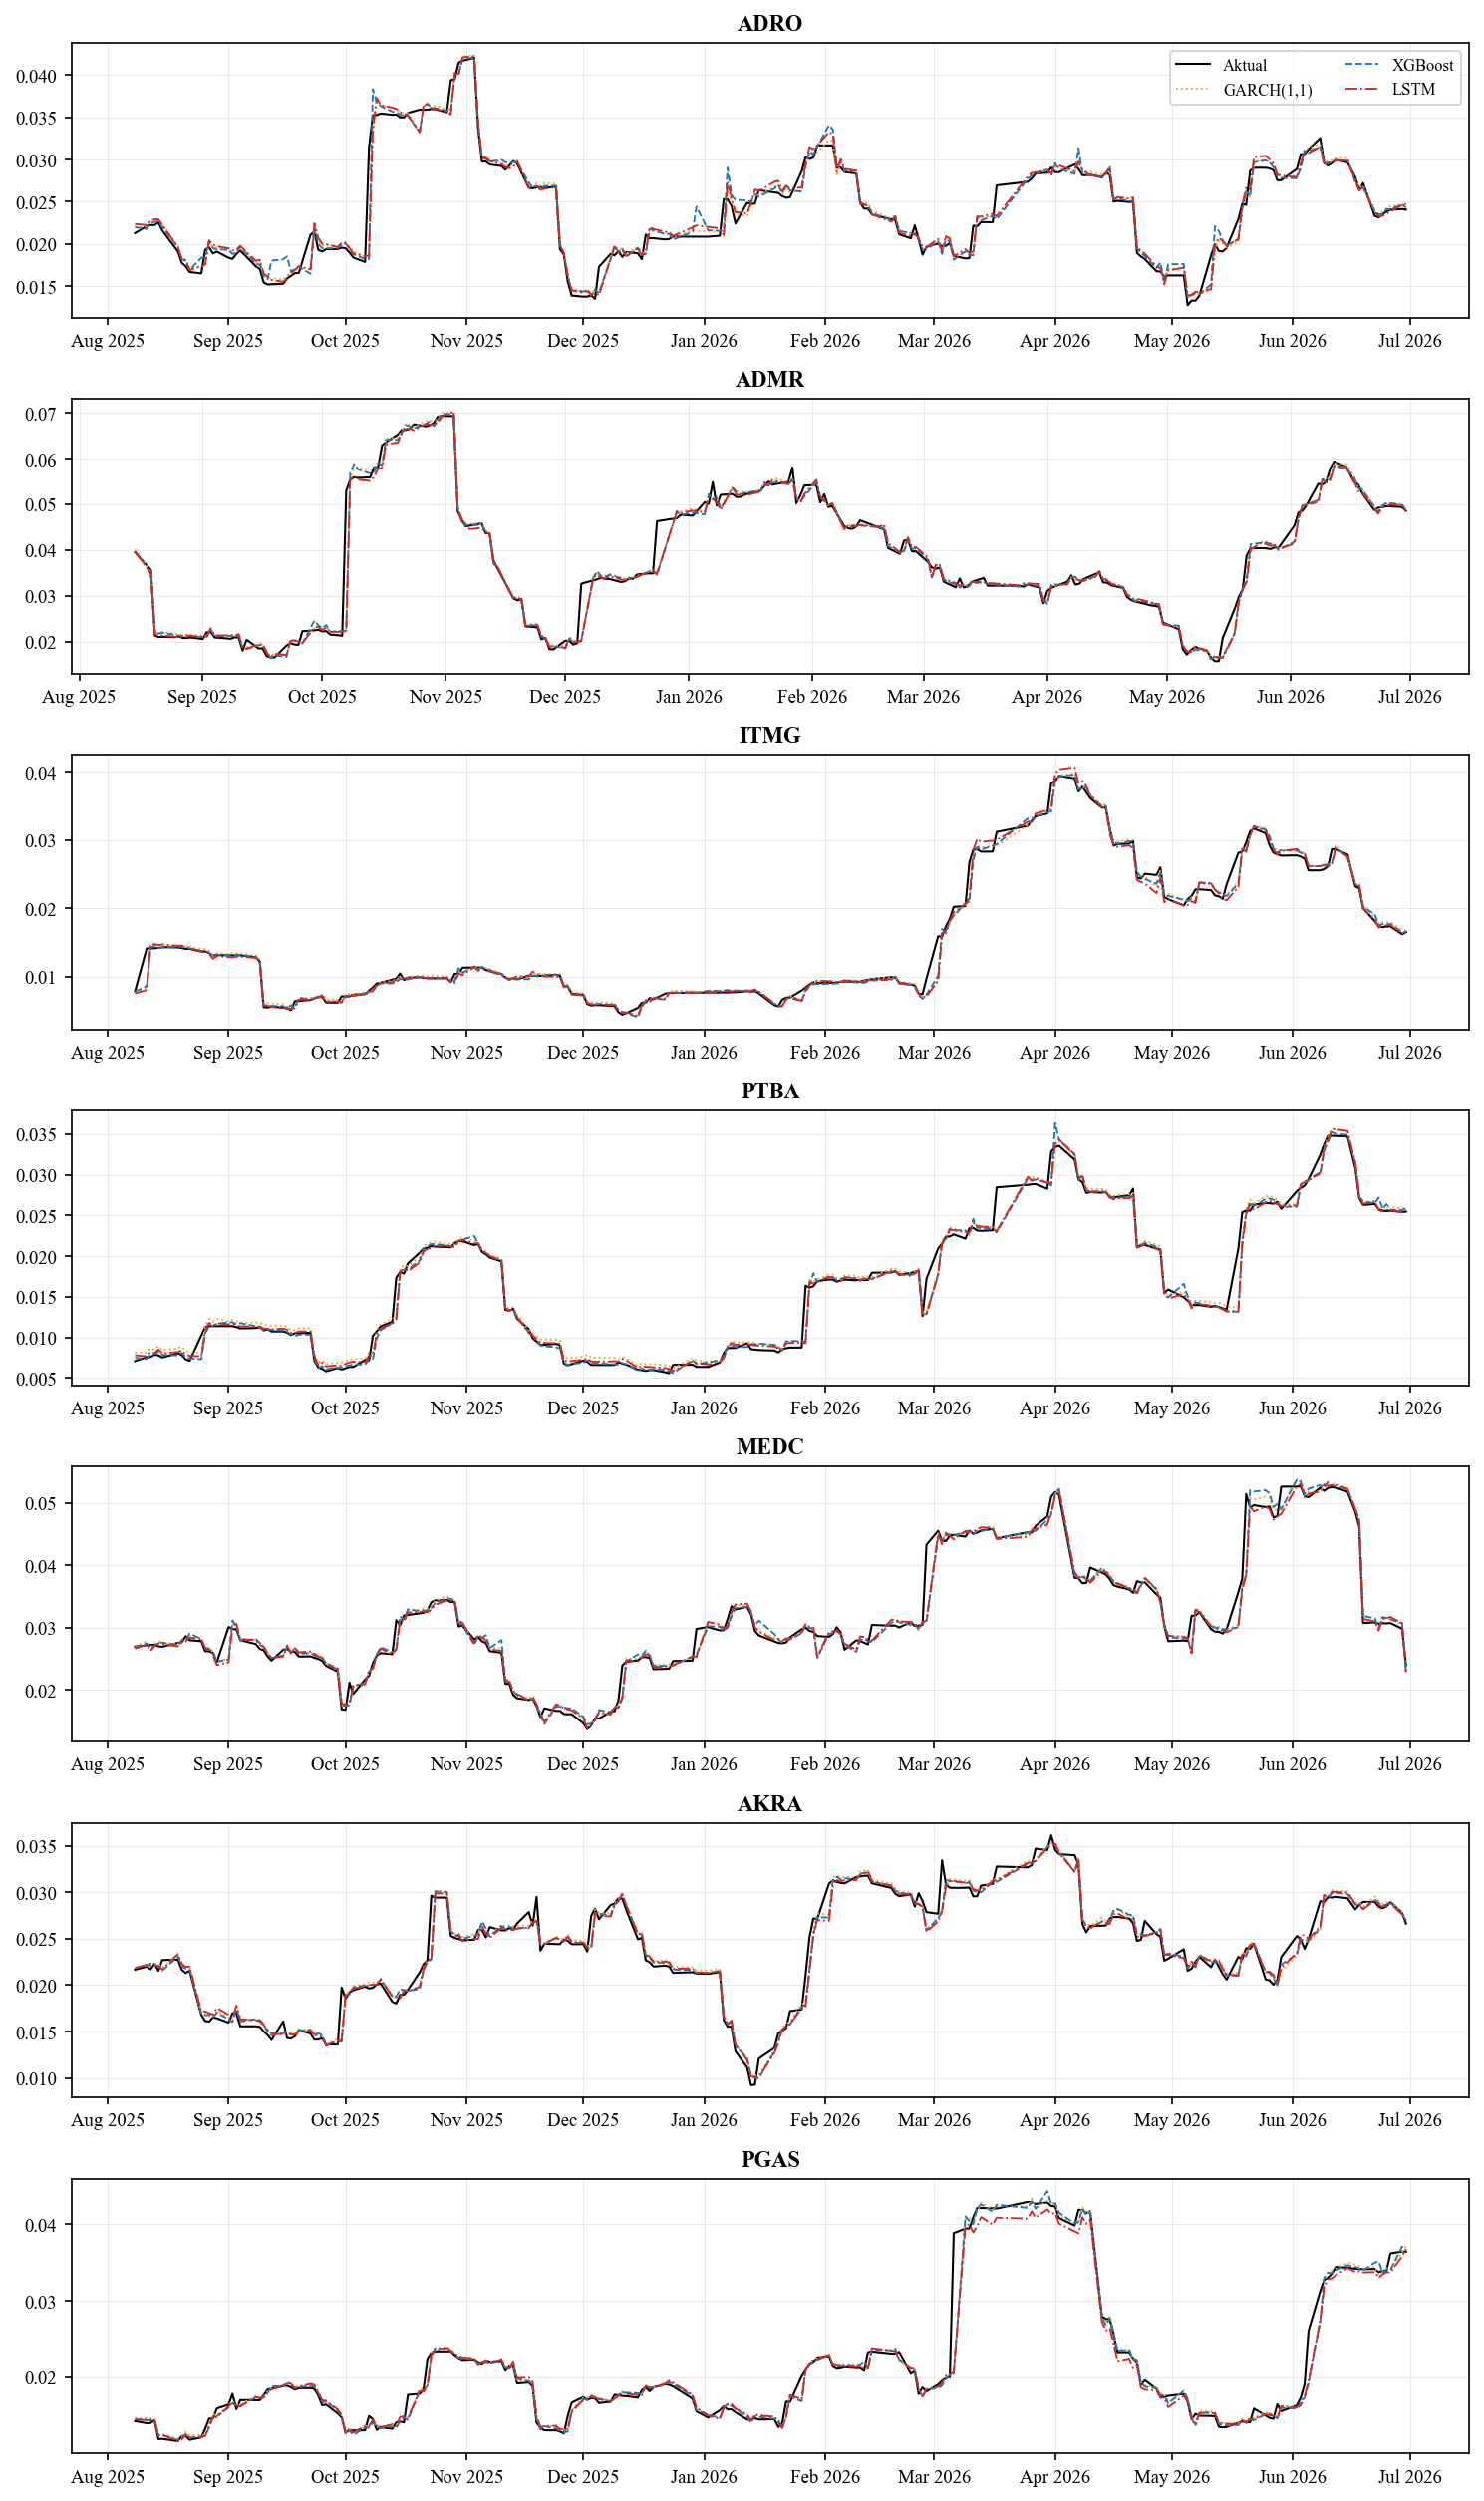

💾 Gambar tersimpan.


In [11]:
import matplotlib.dates as mdates
WARNA = {'Aktual': 'black', 'XGBoost': '#1f77b4', 'LSTM': '#d62728', 'GARCH(1,1)': '#F5A623'}

def plot_emiten(ax, e, legend=True):
    g = df[df.Emiten == e].sort_values('Date')
    for k, ls in [('Aktual', '-'), ('GARCH(1,1)', ':'), ('XGBoost', '--'), ('LSTM', '-.')]:
        ax.plot(g.Date, g[k], color=WARNA[k], lw=1.0 if k == 'Aktual' else 0.9, ls=ls, label=k)
    ax.set_title(e, fontweight='bold'); ax.grid(alpha=0.3, lw=0.4)
    ax.xaxis.set_major_locator(mdates.MonthLocator())              # 1 label per bulan, tidak bertumpuk
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    if legend: ax.legend(fontsize=8, ncol=2)

# ── Gambar ITMG (ukuran sama dengan panel emiten lain → jelas)
EMITEN_ARTIKEL = 'ITMG'
fig, ax = plt.subplots(figsize=(10, 3.2))
plot_emiten(ax, EMITEN_ARTIKEL)
ax.set_ylabel('20-day rolling volatility', fontsize=10)
plt.tight_layout()
plt.savefig(DIR_GAMBAR / f'fig_actual_vs_pred_all_{EMITEN_ARTIKEL}.png', dpi=600, bbox_inches='tight')
plt.show()

# ── Gambar semua emiten (tidak berubah)
fig, axes = plt.subplots(len(URUTAN_EMITEN), 1, figsize=(10, 2.4 * len(URUTAN_EMITEN)))
for i, (ax, e) in enumerate(zip(axes, URUTAN_EMITEN)): plot_emiten(ax, e, legend=(i == 0))
plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'gambar_aktual_vs_prediksi_semua_model.png', dpi=300, bbox_inches='tight')
plt.show()
print('💾 Gambar tersimpan.')